# PULSE: News Article Popularity Analysis

### EDAV Course-End Project

**Objective:** Explore the characteristics associated with online news popularity using exploratory data analysis, statistical methods, and interactive visualizations.

**Dataset:** UCI Online News Popularity Dataset

### Research Questions
1. Which news categories receive the most shares?
2. Does publication day relate to article popularity?
3. Are headline length and sentiment associated with shares?
4. Which article characteristics correlate with popularity?

### Technology Stack
Python · Pandas · NumPy · Seaborn · Matplotlib · SciPy · Plotly · Streamlit

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

# Set up project paths
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "OnlineNewsPopularity.csv"
CHARTS_PATH = PROJECT_ROOT / "outputs" / "charts"
CHARTS_PATH.mkdir(parents=True, exist_ok=True)

# Set visualization style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

# Load dataset
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

print(f"Dataset loaded: {df.shape[0]:,} articles × {df.shape[1]} columns")
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset loaded: 39,644 articles × 61 columns


,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


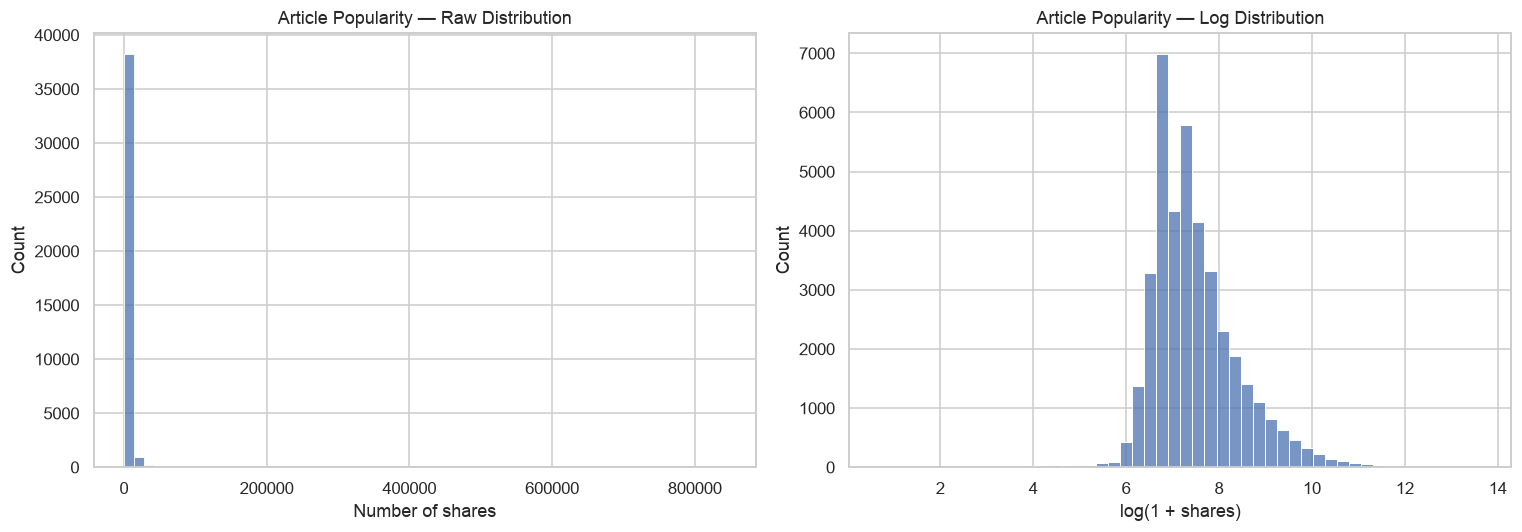

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="shares", bins=60, ax=axes[0])
axes[0].set_title("Article Popularity — Raw Distribution")
axes[0].set_xlabel("Number of shares")

sns.histplot(x=np.log1p(df["shares"]), bins=50, ax=axes[1])
axes[1].set_title("Article Popularity — Log Distribution")
axes[1].set_xlabel("log(1 + shares)")

plt.tight_layout()
plt.savefig(CHARTS_PATH / "popularity_distribution.png", bbox_inches="tight")
plt.show()

## 2. Data Quality and Statistical Overview

This section examines missing values, duplicate records, data types, and descriptive statistics before conducting deeper analysis.

In [4]:
# Data quality audit
print("=" * 55)
print("DATA QUALITY AUDIT")
print("=" * 55)

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Missing cells: {df.isna().sum().sum():,}")

missing_values = df.isna().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("\nColumns with missing values:")
if missing_values.empty:
    print("No missing values found.")
else:
    display(missing_values.to_frame("Missing Count"))

print("\nPopularity statistics:")
display(
    df["shares"]
    .describe()
    .to_frame("Article Shares")
    .round(2)
)

print("\nPopularity percentiles:")
display(
    df["shares"]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .rename("Shares")
    .to_frame()
)

DATA QUALITY AUDIT
Rows: 39,644
Columns: 61
Duplicate rows: 0
Missing cells: 0

Columns with missing values:
No missing values found.

Popularity statistics:


,Article Shares
count,39644.00
mean,3395.38
std,11626.95
min,1.00
25%,946.00
50%,1400.00
75%,2800.00
max,843300.00



Popularity percentiles:


,Shares
0.25,946.0
0.50,1400.0
0.75,2800.0
0.90,6200.0
0.95,10800.0
0.99,31657.0


## 3. News Category Popularity

Compare article popularity across the available news categories using mean and median shares. Median shares are especially useful because a small number of viral articles can strongly affect the mean.

Articles with multiple category flags: 0


,Articles,Mean Shares,Median Shares
category,,,
Social Media,2323,3629.38,2100.0
Other / Unclassified,6134,5945.19,1900.0
Lifestyle,2099,3682.12,1700.0
Technology,7346,3072.28,1700.0
Business,6258,3063.02,1400.0
Entertainment,7057,2970.49,1200.0
World,8427,2287.73,1100.0


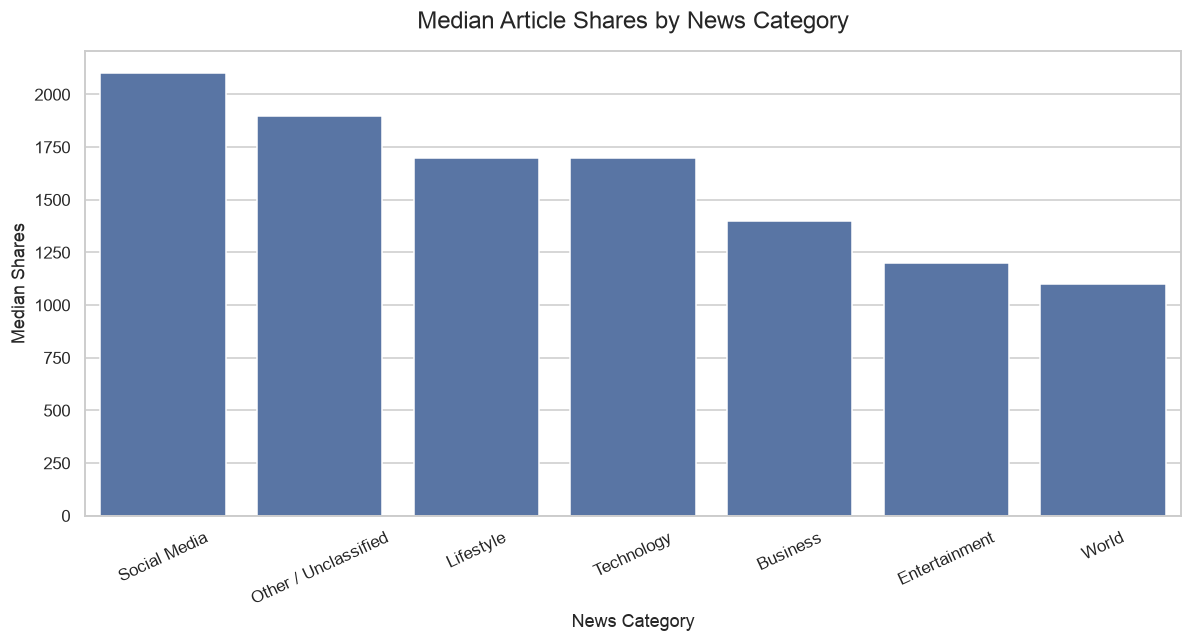

In [5]:
# Map category indicator columns to readable labels
category_columns = {
    "data_channel_is_lifestyle": "Lifestyle",
    "data_channel_is_entertainment": "Entertainment",
    "data_channel_is_bus": "Business",
    "data_channel_is_socmed": "Social Media",
    "data_channel_is_tech": "Technology",
    "data_channel_is_world": "World"
}

category_flags = df[list(category_columns)].fillna(0).eq(1)

# Check whether any articles have multiple category flags
print("Articles with multiple category flags:",
      (category_flags.sum(axis=1) > 1).sum())

# Convert category flags to labels
category = category_flags.idxmax(axis=1).map(category_columns)
category = category.where(category_flags.any(axis=1), "Other / Unclassified")

df["category"] = category

category_summary = (
    df.groupby("category")["shares"]
    .agg(["count", "mean", "median"])
    .rename(columns={
        "count": "Articles",
        "mean": "Mean Shares",
        "median": "Median Shares"
    })
    .sort_values("Median Shares", ascending=False)
)

display(category_summary.round(2))

# Compare median shares across categories
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=df,
    x="category",
    y="shares",
    estimator=np.median,
    errorbar=None,
    order=category_summary.index,
    ax=ax
)

ax.set_title("Median Article Shares by News Category", fontsize=16, pad=15)
ax.set_xlabel("News Category")
ax.set_ylabel("Median Shares")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(CHARTS_PATH / "category_popularity.png", bbox_inches="tight")
plt.show()

## 4. Publication Day and Popularity

Compare the distribution of article shares across weekdays and weekends to explore whether publication timing is associated with popularity.

Articles with multiple weekday flags: 0


,Articles,Mean Shares,Median Shares
weekday,,,
Monday,6661,3647.03,1400.0
Tuesday,7390,3202.50,1300.0
Wednesday,7435,3303.41,1300.0
Thursday,7267,3178.60,1400.0
Friday,5701,3285.18,1500.0
Saturday,2453,4078.19,2000.0
Sunday,2737,3746.74,1900.0


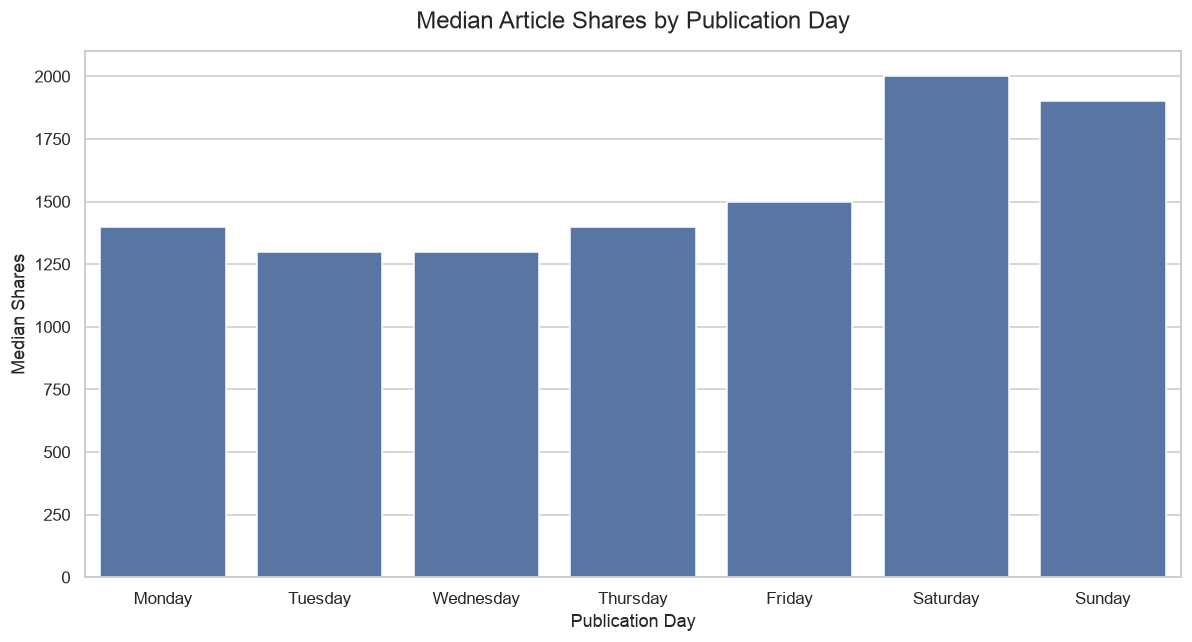

In [6]:
weekday_columns = {
    "weekday_is_monday": "Monday",
    "weekday_is_tuesday": "Tuesday",
    "weekday_is_wednesday": "Wednesday",
    "weekday_is_thursday": "Thursday",
    "weekday_is_friday": "Friday",
    "weekday_is_saturday": "Saturday",
    "weekday_is_sunday": "Sunday"
}

weekday_flags = df[list(weekday_columns)].fillna(0).eq(1)

print("Articles with multiple weekday flags:",
      (weekday_flags.sum(axis=1) > 1).sum())

weekday = weekday_flags.idxmax(axis=1).map(weekday_columns)
weekday = weekday.where(weekday_flags.any(axis=1), "Unknown")
df["weekday"] = weekday

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = (
    df[df["weekday"] != "Unknown"]
    .groupby("weekday")["shares"]
    .agg(["count", "mean", "median"])
    .reindex(weekday_order)
)

weekday_summary.columns = ["Articles", "Mean Shares", "Median Shares"]
display(weekday_summary.round(2))

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=df[df["weekday"] != "Unknown"],
    x="weekday",
    y="shares",
    estimator=np.median,
    errorbar=None,
    order=weekday_order,
    ax=ax
)

ax.set_title("Median Article Shares by Publication Day", fontsize=16, pad=15)
ax.set_xlabel("Publication Day")
ax.set_ylabel("Median Shares")

plt.tight_layout()
plt.savefig(CHARTS_PATH / "weekday_popularity.png", bbox_inches="tight")
plt.show()

## 5. Article Characteristics and Popularity

Investigate whether headline length, article length, sentiment, and multimedia features are associated with the number of social media shares.

In [7]:
# Create readable feature names
df["headline_words"] = df["n_tokens_title"]
df["article_words"] = df["n_tokens_content"]
df["positive_sentiment"] = df["global_sentiment_polarity"]

# Correlations with article popularity
features = {
    "Headline Length": "headline_words",
    "Article Length": "article_words",
    "Positive Sentiment": "positive_sentiment",
    "Number of Images": "num_imgs",
    "Number of Videos": "num_videos",
    "Number of Links": "num_hrefs",
    "Title Sentiment": "title_sentiment_polarity"
}

correlation_rows = []

for label, column in features.items():
    valid = df[[column, "shares"]].dropna()

    pearson_r, pearson_p = stats.pearsonr(
        valid[column], valid["shares"]
    )

    spearman_r, spearman_p = stats.spearmanr(
        valid[column], valid["shares"]
    )

    correlation_rows.append({
        "Feature": label,
        "Pearson Correlation": pearson_r,
        "Pearson p-value": pearson_p,
        "Spearman Correlation": spearman_r,
        "Spearman p-value": spearman_p
    })

correlation_results = pd.DataFrame(correlation_rows)
display(correlation_results.round(4))


,Feature,Pearson Correlation,Pearson p-value,Spearman Correlation,Spearman p-value
0,Headline Length,0.0088,0.0803,-0.0403,0.0000
1,Article Length,0.0025,0.6244,0.0097,0.0541
2,Positive Sentiment,0.0042,0.4072,0.0796,0.0000
3,Number of Images,0.0394,0.0000,0.0831,0.0000
4,Number of Videos,0.0239,0.0000,0.0485,0.0000
5,Number of Links,0.0454,0.0000,0.0900,0.0000
6,Title Sentiment,0.0128,0.0110,0.0569,0.0000


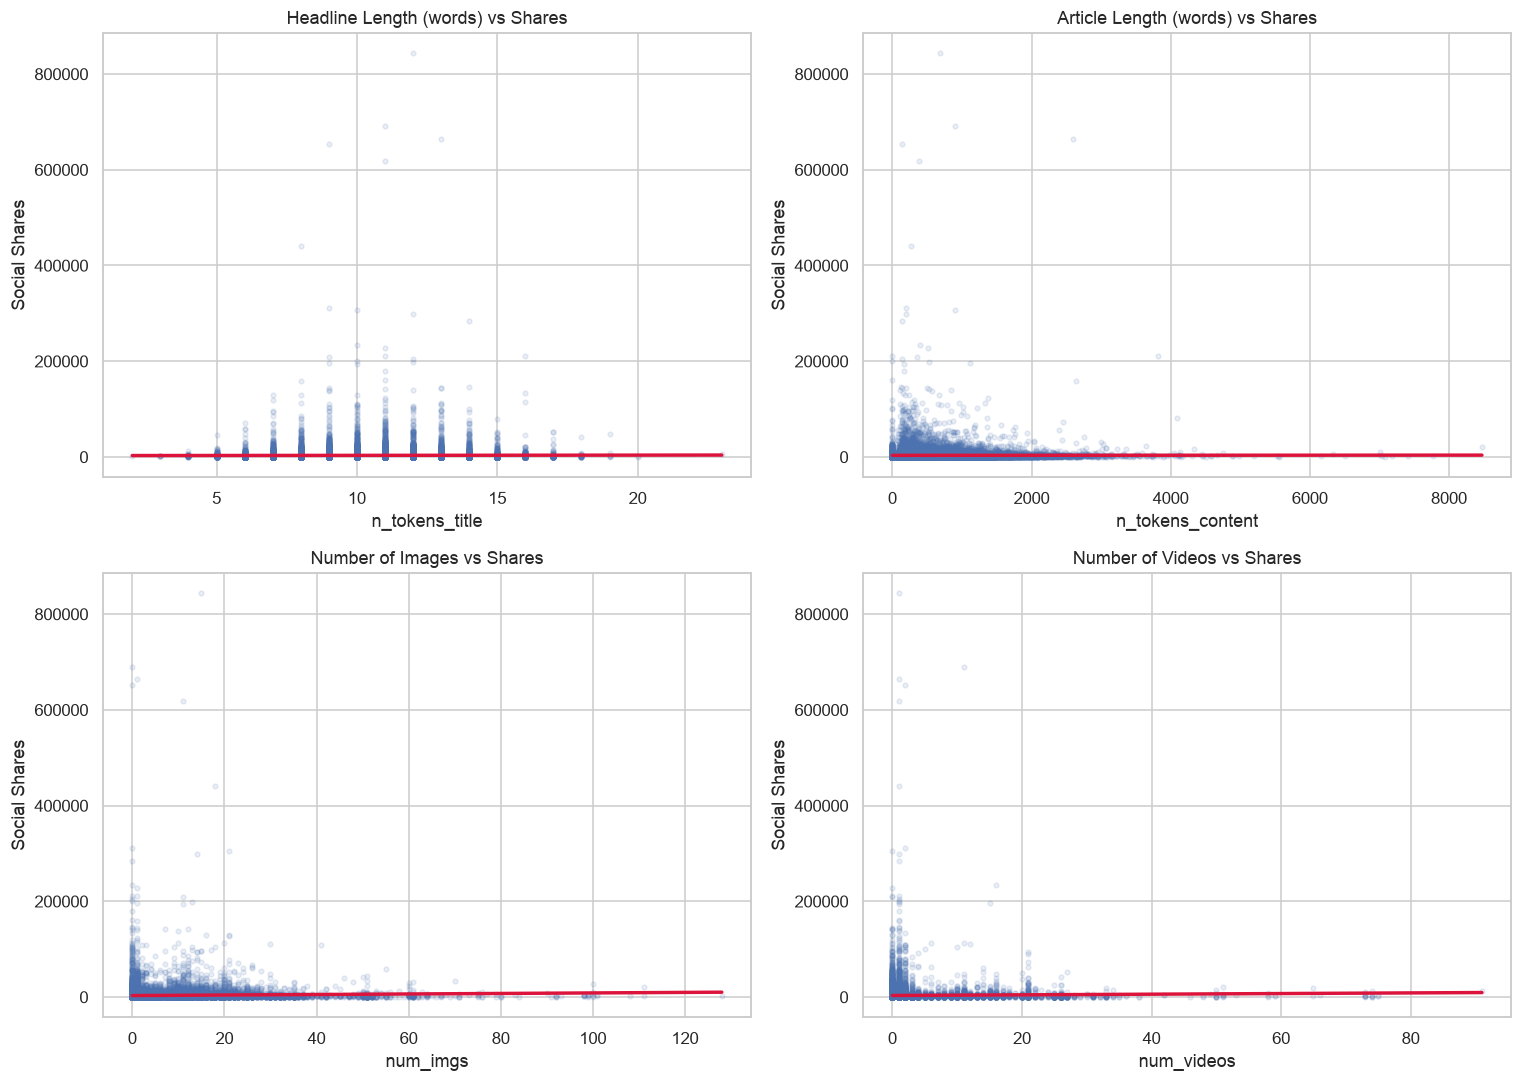

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_features = [
    ("n_tokens_title", "Headline Length (words)"),
    ("n_tokens_content", "Article Length (words)"),
    ("num_imgs", "Number of Images"),
    ("num_videos", "Number of Videos")
]

for ax, (column, label) in zip(axes.flat, plot_features):
    sns.regplot(
        data=df,
        x=column,
        y="shares",
        scatter_kws={"alpha": 0.12, "s": 10},
        line_kws={"color": "crimson"},
        ax=ax
    )
    ax.set_title(f"{label} vs Shares")
    ax.set_ylabel("Social Shares")

plt.tight_layout()
plt.savefig(
    CHARTS_PATH / "article_features_vs_shares.png",
    bbox_inches="tight"
)
plt.show()


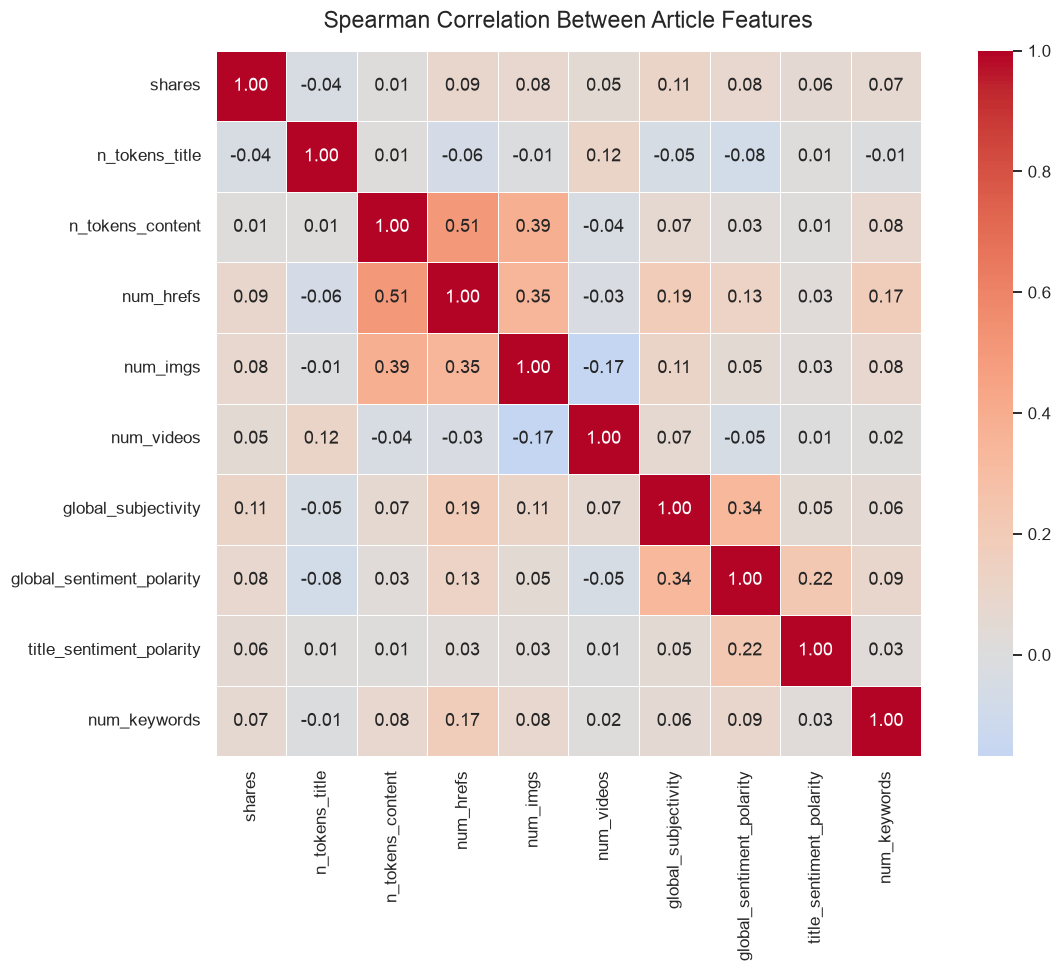

In [10]:
heatmap_features = [
    "shares",
    "n_tokens_title",
    "n_tokens_content",
    "num_hrefs",
    "num_imgs",
    "num_videos",
    "global_subjectivity",
    "global_sentiment_polarity",
    "title_sentiment_polarity",
    "num_keywords"
]

corr_matrix = df[heatmap_features].corr(method="spearman")

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Between Article Features", fontsize=15, pad=15)
plt.tight_layout()
plt.savefig(CHARTS_PATH / "correlation_heatmap.png", bbox_inches="tight")
plt.show()


In [11]:
# Export summary tables
category_summary.to_csv(
    PROJECT_ROOT / "outputs" / "category_summary.csv"
)

weekday_summary.to_csv(
    PROJECT_ROOT / "outputs" / "weekday_summary.csv"
)

correlation_results.to_csv(
    PROJECT_ROOT / "outputs" / "feature_correlations.csv",
    index=False
)

print("Analysis outputs saved successfully.")
print("Charts folder:", CHARTS_PATH)


Analysis outputs saved successfully.
Charts folder: /Users/kailash/Documents/News-Article-Popularity-Analysis/outputs/charts


## 6. Statistical Hypothesis Testing

### Research question
Does article popularity differ between weekday and weekend publications?

- **H₀:** The weekday and weekend share distributions are the same.
- **H₁:** The weekday and weekend share distributions differ.

We use the Mann–Whitney U test because article shares are strongly right-skewed. Statistical significance will be assessed at α = 0.05.

In [12]:
from scipy.stats import mannwhitneyu

# Separate the observations
weekday_shares = df.loc[df["is_weekend"] == 0, "shares"].dropna()
weekend_shares = df.loc[df["is_weekend"] == 1, "shares"].dropna()

# Perform the two-sided test
u_statistic, p_value = mannwhitneyu(
    weekday_shares,
    weekend_shares,
    alternative="two-sided"
)

# Calculate rank-based effect size
n_weekday = len(weekday_shares)
n_weekend = len(weekend_shares)

rank_biserial = (
    2 * u_statistic / (n_weekday * n_weekend)
) - 1

print("WEEKDAY VS WEEKEND")
print("=" * 40)
print(f"Weekday articles: {n_weekday:,}")
print(f"Weekend articles: {n_weekend:,}")
print(f"Weekday median shares: {weekday_shares.median():,.0f}")
print(f"Weekend median shares: {weekend_shares.median():,.0f}")
print(f"Mann–Whitney U statistic: {u_statistic:,.0f}")
print(f"P-value: {p_value:.6g}")
print(f"Rank-biserial effect size: {rank_biserial:.4f}")

if p_value < 0.05:
    print("\nConclusion: Reject H₀ at the 5% significance level.")
    print("The distributions show a statistically significant difference.")
else:
    print("\nConclusion: Insufficient evidence to reject H₀.")

print("Note: Statistical significance does not imply a large practical effect.")

WEEKDAY VS WEEKEND
Weekday articles: 34,454
Weekend articles: 5,190
Weekday median shares: 1,400
Weekend median shares: 1,900
Mann–Whitney U statistic: 66,197,400
P-value: 1.87152e-200
Rank-biserial effect size: -0.2596

Conclusion: Reject H₀ at the 5% significance level.
The distributions show a statistically significant difference.
Note: Statistical significance does not imply a large practical effect.
